# Análise dos logs de regressão simbólica OTFT — Org4

Notebook independente para analisar logs, comparar equações candidatas e métodos clássicos, avaliar por curva e exportar figuras e especificações.

## 1. Caminhos e seleção da execução

`RUN_NAME` aponta para `logs/org4_synthetic_notebook`. Os dados train/test_id/test_ood são carregados de `data/synthetic_org4`. Execute primeiro o notebook de experimento para criar os logs.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_workspace(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "OTFT-SR/data").is_dir() and (candidate / "LLM-SR").is_dir():
            return candidate
    raise FileNotFoundError("Não encontrei a raiz do workspace OTFT-SR.")

WORKSPACE_ROOT = find_workspace(Path.cwd().resolve())
OTFT_SR_ROOT = WORKSPACE_ROOT / "OTFT-SR"

# Selecione uma pasta em OTFT-SR/logs. O nome synthetic ativa os dados bivariados.
ORG_NAME = "Org4"
RUN_NAME = "org4_synthetic_notebook"
RUN_DIRECTORY = OTFT_SR_ROOT / "logs" / RUN_NAME
SAMPLES_DIRECTORY = RUN_DIRECTORY / "samples"
DATASET_MODE = "synthetic" if "synthetic" in RUN_NAME.lower() else "measured"

if DATASET_MODE == "synthetic":
    DATA_DIRECTORY = OTFT_SR_ROOT / "data/synthetic_org4"
    TRAIN_PATH = DATA_DIRECTORY / "train.csv"
    TEST_ID_PATH = DATA_DIRECTORY / "test_id.csv"
    HOLDOUT_PATH = DATA_DIRECTORY / "test_ood.csv"
    FEATURE_COLUMNS = ["VGS_abs_V", "VDS_abs_V"]
    SPLIT_LABELS = {"treino": "treino", "test_id": "test_id", "teste_extrapolacao": "test_ood"}
else:
    DATA_DIRECTORY = OTFT_SR_ROOT / "data"
    TRAIN_PATH = DATA_DIRECTORY / "train.csv"
    TEST_ID_PATH = None
    HOLDOUT_PATH = DATA_DIRECTORY / "test_extrapolation.csv"
    FEATURE_COLUMNS = ["VGS_abs_V"]
    SPLIT_LABELS = {"treino": "treino", "teste_extrapolacao": "teste_extrapolacao"}

TARGET_COLUMN = "log10_ID_abs_A"
plt.style.use("seaborn-v0_8-whitegrid")
print("Execução:", RUN_DIRECTORY)
print("Modo de dados:", DATASET_MODE, "| entradas:", FEATURE_COLUMNS)

Execução: /home/ymws/Documentos/llm-sr/OTFT-SR/logs/org4_synthetic_notebook
Modo de dados: synthetic | entradas: ['VGS_abs_V', 'VDS_abs_V']


## 2. Dados e cobertura da curva

In [2]:
train_df = pd.read_csv(TRAIN_PATH)
holdout_df = pd.read_csv(HOLDOUT_PATH)
evaluation_frames = {"treino": train_df}
if TEST_ID_PATH is not None:
    test_id_df = pd.read_csv(TEST_ID_PATH)
    evaluation_frames["test_id"] = test_id_df
evaluation_frames["teste_extrapolacao"] = holdout_df

summary = pd.concat({
    split_name: frame[[*FEATURE_COLUMNS, TARGET_COLUMN]].describe().T
    for split_name, frame in evaluation_frames.items()
}, axis=1)
display(summary.round(5))

if len(FEATURE_COLUMNS) == 1:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for split_name, frame in evaluation_frames.items():
        x_values = frame[FEATURE_COLUMNS[0]].to_numpy()
        sort_index = np.argsort(x_values)
        ax.plot(x_values[sort_index], frame[TARGET_COLUMN].to_numpy()[sort_index],
                marker=".", ms=4, label=SPLIT_LABELS[split_name])
    ax.set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Curva de transferência e região reservada")
    ax.legend()
else:
    fig, axes = plt.subplots(1, len(evaluation_frames), figsize=(5 * len(evaluation_frames), 4), sharex=True, sharey=True)
    if len(evaluation_frames) == 1:
        axes = [axes]
    for ax, (split_name, frame) in zip(axes, evaluation_frames.items()):
        points = ax.scatter(frame["VGS_abs_V"], frame[TARGET_COLUMN],
                            c=frame["VDS_abs_V"], s=9, alpha=.65, cmap="viridis")
        ax.set(title=SPLIT_LABELS[split_name], xlabel="|VGS| (V)", ylabel="log10(|ID| / A)")
        fig.colorbar(points, ax=ax, label="|VDS| (V)")
    fig.suptitle("Curvas sintéticas: polarização de dreno indicada pela cor")
plt.tight_layout()
plt.show()

treino                                                    \
                 count      mean       std       min       25%       50%   
VGS_abs_V       1200.0  37.00000  14.87670   0.00000  26.00000  40.00000   
VDS_abs_V       1200.0  41.00000  20.24196   0.00000  26.71114  42.00000   
log10_ID_abs_A  1200.0  -4.47228   1.37655 -10.69897  -4.63571  -4.28473   

                                   test_id            ...                      \
                     75%       max   count      mean  ...       75%       max   
VGS_abs_V       46.00000  80.00000   750.0  36.80000  ...  48.00000  80.00000   
VDS_abs_V       53.28886  80.00000   750.0  40.80000  ...  55.15677  80.00000   
log10_ID_abs_A  -3.69596  -3.31841   750.0  -4.42702  ...  -3.73795  -3.33493   

               teste_extrapolacao                                          \
                            count      mean       std       min       25%   
VGS_abs_V                  1800.0  70.00000  18.98125   0.00000  64.00000   
VDS_abs_V                  1800.0  41.50000  21.49681   0.00000  24.04270   
log10_ID_abs_A             1800.0  -3.95302   1.63342 -10.69897  -3.75386   

                                              
                     50%       75%       max  
VGS_abs_V       70.00000  84.50000  90.00000  
VDS_abs_V       47.88259  55.95730  80.00000  
log10_ID_abs_A  -3.43314  -3.31231  -3.10088  

[3 rows x 24 columns]

<Figure size 1500x400 with 6 Axes>

## 3. Carregamento dos registros de amostra

Cada JSON contém a ordem, o score e o código da função avaliada. Registros malformados são ignorados e scores não numéricos permanecem ausentes.

In [3]:
records = []
if SAMPLES_DIRECTORY.exists():
    for sample_path in sorted(SAMPLES_DIRECTORY.glob("samples_*.json")):
        try:
            payload = json.loads(sample_path.read_text(encoding="utf-8"))
            records.append({
                "arquivo": sample_path.name,
                "ordem": payload.get("sample_order"),
                "score": payload.get("score"),
                "function": payload.get("function", ""),
            })
        except (OSError, json.JSONDecodeError) as error:
            print(f"Registro ignorado {sample_path.name}: {error}")

log_df = pd.DataFrame(records, columns=["arquivo", "ordem", "score", "function"])
if not log_df.empty:
    log_df["ordem"] = pd.to_numeric(log_df["ordem"], errors="coerce")
    log_df["score"] = pd.to_numeric(log_df["score"], errors="coerce")
valid_df = log_df.dropna(subset=["score"]).copy()
print(f"Arquivos lidos: {len(log_df)} | scores válidos: {len(valid_df)}")
display(log_df.head(10))

Arquivos lidos: 101 | scores válidos: 47


,arquivo,ordem,score,function
0,samples_0.json,0,-0.953419,"def equation(gate_voltage_abs: np.ndarray, dra..."
1,samples_10.json,10,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
2,samples_100.json,100,-1990.995711,"def equation(gate_voltage_abs: np.ndarray, dra..."
3,samples_101.json,101,-0.610853,"def equation(gate_voltage_abs: np.ndarray, dra..."
4,samples_11.json,11,-1.344058,"def equation(gate_voltage_abs: np.ndarray, dra..."
5,samples_12.json,12,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
6,samples_13.json,13,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
7,samples_14.json,14,-0.465659,"def equation(gate_voltage_abs: np.ndarray, dra..."
8,samples_15.json,15,NaN,"def equation(gate_voltage_abs: np.ndarray, dra..."
9,samples_16.json,16,-6973.317547,"def equation(gate_voltage_abs: np.ndarray, dra..."


## 4. Distribuição e evolução do score

Como score = -MSE, valores mais altos (mais próximos de zero) representam menor erro no treino. O RMSE abaixo está na escala logarítmica da corrente.

,score
count,4.700000e+01
mean,-1.344635e+43
std,9.218354e+43
min,-6.319785e+44
25%,-2.683915e+01
50%,-9.462132e-01
75%,-4.849829e-01
90%,-4.656588e-01
max,-4.481866e-01


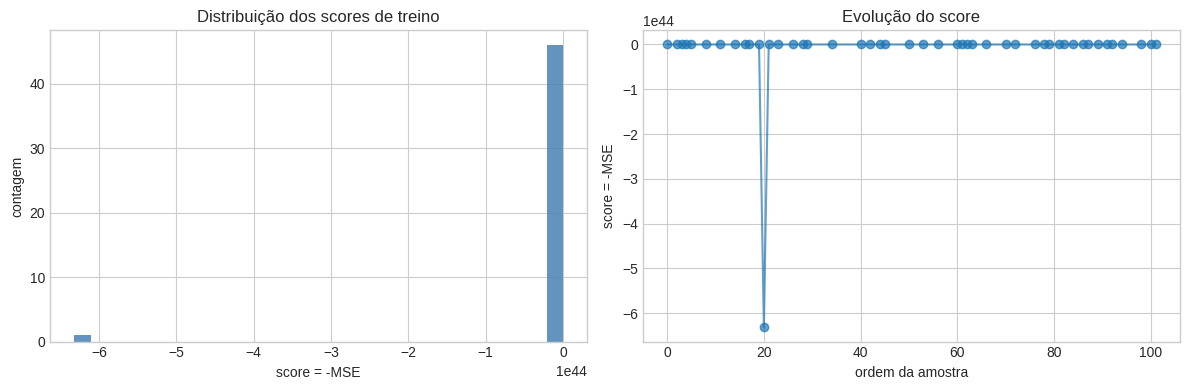

Melhor RMSE log10 treino: 0.6694673834318339


In [4]:
if valid_df.empty:
    print("Nenhuma amostra com score numérico foi encontrada nesta execução.")
else:
    display(valid_df["score"].describe(percentiles=[.25, .5, .75, .9]).to_frame("score").round(8))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(valid_df.score, bins=min(30, max(5, len(valid_df))), color="steelblue", alpha=.85)
    axes[0].set(xlabel="score = -MSE", ylabel="contagem", title="Distribuição dos scores de treino")
    ordered = valid_df.dropna(subset=["ordem"]).sort_values("ordem")
    axes[1].plot(ordered.ordem, ordered.score, "o-", alpha=.7)
    axes[1].set(xlabel="ordem da amostra", ylabel="score = -MSE", title="Evolução do score")
    plt.tight_layout()
    plt.show()

    valid_df["RMSE_log10"] = np.sqrt(np.maximum(-valid_df.score, 0))
    valid_df["fator_multiplicativo_aprox"] = 10 ** valid_df["RMSE_log10"]
    print("Melhor RMSE log10 treino:", float(valid_df.RMSE_log10.min()))

## 5. Melhores expressões e diversidade

In [5]:
if valid_df.empty:
    print("Sem candidatas válidas para ranquear.")
else:
    best_df = valid_df.sort_values("score", ascending=False).head(10)
    display(best_df[["ordem", "score", "arquivo"]].reset_index(drop=True))
    for _, row in best_df.head(5).iterrows():
        print(f"\n{row['arquivo']} | amostra={row['ordem']} | score={row['score']:.8g}")
        print(str(row["function"]).strip() or "(função vazia)")
    normalized = valid_df["function"].fillna("").str.strip()
    print("Expressões únicas entre amostras válidas:", normalized.nunique())
    print("Total de amostras válidas:", len(valid_df))

,ordem,score,arquivo
0,84,-0.448187,samples_84.json
1,29,-0.465659,samples_29.json
2,66,-0.465659,samples_66.json
3,14,-0.465659,samples_14.json
4,2,-0.465659,samples_2.json
5,8,-0.465659,samples_8.json
6,79,-0.465659,samples_79.json
7,40,-0.477027,samples_40.json
8,86,-0.477027,samples_86.json
9,60,-0.477027,samples_60.json



samples_84.json | amostra=84 | score=-0.44818658
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Further improved version of the function that includes a cubic term for drain_voltage_abs and a quadratic term for gate_voltage_abs."""
    return (
        parameters[0]
        + parameters[1] * gate_voltage_abs
        + parameters[2] * gate_voltage_abs**2
        + parameters[3] * drain_voltage_abs
        + parameters[4] * drain_voltage_abs**2
        + parameters[5] * drain_voltage_abs**3
    )

samples_29.json | amostra=29 | score=-0.46565878
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Improved polynomial model for log10(|ID|/A)."""
    a0, a1, a2, a3, a4, a5, a6, a7, a8, a9, a10, a11 = parameters
    return a0 + a1 * gate_volt

## 6. Reajuste e teste da melhor equação LLM-SR

Seleciona a amostra de maior score na execução escolhida. Como os parâmetros otimizados não foram gravados nos logs, a expressão é reajustada somente no treino por BFGS e então aplicada sem novo ajuste ao holdout. O interpretador abaixo identifica os argumentos da candidata e associa gate_voltage_abs e drain_voltage_abs às colunas correspondentes. Aceita somente operações aritméticas e funções NumPy explicitamente listadas; não executa código arbitrário dos logs.

Melhor equação: samples_84.json | score registrado=-0.448186577479
Entradas da equação: ['gate_voltage_abs', 'drain_voltage_abs']
Parâmetros reajustados no treino (6): [-1.09573593e+01  2.39798544e-01 -2.24309261e-03  1.00949952e-01
 -2.36818214e-03  1.68605322e-05]
Convergência do otimizador: False (Desired error not necessarily achieved due to precision loss.)
Equação registrada:
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Further improved version of the function that includes a cubic term for drain_voltage_abs and a quadratic term for gate_voltage_abs."""
    return (
        parameters[0]
        + parameters[1] * gate_voltage_abs
        + parameters[2] * gate_voltage_abs**2
        + parameters[3] * drain_voltage_abs
        + parameters[4] * drain_voltage_abs**2
        + parameters[5] * drain_voltage_abs**3
    )


,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
conjunto,,,,,
treino,0.448186,0.669467,0.439387,0.763281,4.671616
test_id,0.429197,0.655131,0.437186,0.732831,4.519927
teste_extrapolacao,2.861001,1.691449,1.223637,-0.072914,49.141614


RMSE de treino refeito: 0.669467; RMSE correspondente ao score logado: 0.669467
Previsões do holdout salvas em: /home/ymws/Documentos/llm-sr/OTFT-SR/results/org4_synthetic_notebook_best_candidate_holdout.csv


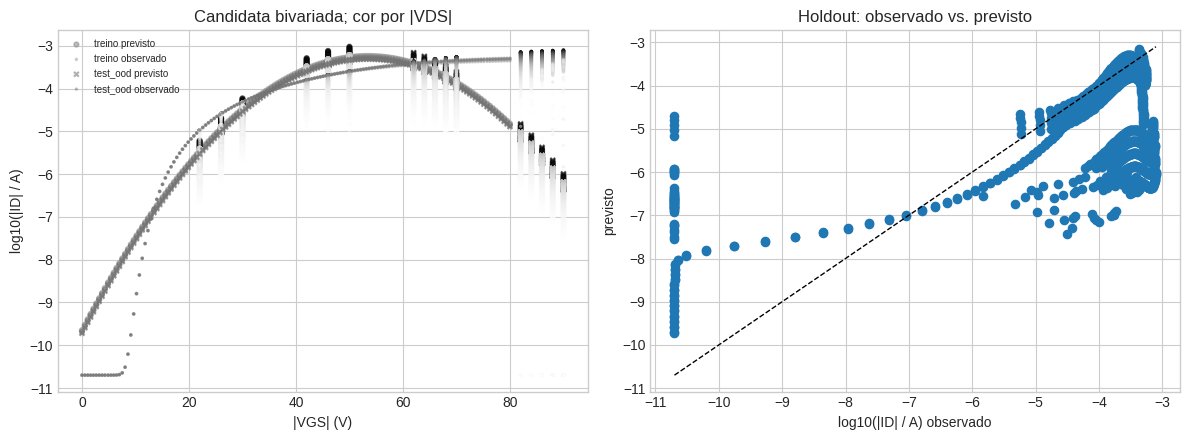

,VGS_abs_V,VDS_abs_V,log10_ID_abs_A,curve_id,curve_family,fixed_voltage_abs_V,sweep_voltage_abs_V,log10_ID_predito_A,residuo_log10,ID_observado_A,ID_predito_A
0,80.000000,48.000000,-3.302877,transfer-neg48V_synth_003,transfer,48.0,80.000000,-4.875322,1.572445,0.000498,0.000013
1,79.466311,48.000000,-3.304588,transfer-neg48V_synth_003,transfer,48.0,79.466311,-4.812401,1.507813,0.000496,0.000015
2,78.932622,48.000000,-3.306358,transfer-neg48V_synth_003,transfer,48.0,78.932622,-4.750757,1.444399,0.000494,0.000018
3,78.398933,48.000000,-3.308190,transfer-neg48V_synth_003,transfer,48.0,78.398933,-4.690391,1.382201,0.000492,0.000020
4,77.865244,48.000000,-3.310087,transfer-neg48V_synth_003,transfer,48.0,77.865244,-4.631303,1.321216,0.000490,0.000023
...,...,...,...,...,...,...,...,...,...,...,...
1795,90.000000,2.134756,-10.698970,output-neg90V_synth_004,output,90.0,2.134756,-7.339665,-3.359305,0.000000,0.000000
1796,90.000000,1.601067,-10.698970,output-neg90V_synth_004,output,90.0,1.601067,-7.388914,-3.310056,0.000000,0.000000
1797,90.000000,1.067378,-4.498335,output-neg90V_synth_004,output,90.0,1.067378,-7.439466,2.941131,0.000032,0.000000
1798,90.000000,0.533689,-10.698970,output-neg90V_synth_004,output,90.0,0.533689,-7.491337,-3.207634,0.000000,0.000000


In [6]:
import ast
import operator
from scipy.optimize import minimize

if valid_df.empty:
    raise ValueError("A execução selecionada não contém candidata com score válido.")

best_logged_row = valid_df.sort_values("score", ascending=False).iloc[0]
best_sample_path = SAMPLES_DIRECTORY / best_logged_row["arquivo"]
best_sample_payload = json.loads(best_sample_path.read_text(encoding="utf-8"))
best_function_source = best_sample_payload["function"]
best_score_logged = float(best_sample_payload["score"])
best_function_ast = next(
    node for node in ast.parse(best_function_source).body
    if isinstance(node, ast.FunctionDef) and node.name == "equation"
)

function_arguments = [argument.arg for argument in best_function_ast.args.args]
parameter_argument = next((name for name in function_arguments if name in {"parameters", "params"}), None)
if parameter_argument is None:
    raise ValueError(f"Assinatura sem vetor de parâmetros reconhecido: {function_arguments}")
candidate_input_names = [name for name in function_arguments if name != parameter_argument]
argument_to_column = {
    "gate_voltage_abs": "VGS_abs_V",
    "drain_voltage_abs": "VDS_abs_V",
}
unknown_arguments = set(candidate_input_names) - set(argument_to_column)
if unknown_arguments:
    raise ValueError(f"Entradas da candidata sem coluna de dados correspondente: {sorted(unknown_arguments)}")
candidate_feature_columns = [argument_to_column[name] for name in candidate_input_names]
missing_columns = set(candidate_feature_columns + [TARGET_COLUMN]) - set(train_df.columns)
if missing_columns:
    raise ValueError(
        f"A equação requer colunas ausentes em {TRAIN_PATH}: {sorted(missing_columns)}. "
        "Para curvas sintéticas, escolha um RUN_NAME contendo 'synthetic'."
    )
if candidate_feature_columns != FEATURE_COLUMNS:
    raise ValueError(
        f"Entradas do log ({candidate_feature_columns}) não correspondem ao modo de dados "
        f"selecionado ({FEATURE_COLUMNS}). Escolha o diretório de execução correspondente."
    )

binary_operators = {
    ast.Add: operator.add, ast.Sub: operator.sub, ast.Mult: operator.mul,
    ast.Div: operator.truediv, ast.Pow: operator.pow,
}
unary_operators = {ast.UAdd: operator.pos, ast.USub: operator.neg}
numpy_functions = {
    "abs": np.abs, "log": np.log, "log10": np.log10, "sqrt": np.sqrt,
    "exp": np.exp, "sin": np.sin, "cos": np.cos, "tanh": np.tanh,
    "cbrt": np.cbrt, "square": np.square, "maximum": np.maximum, "minimum": np.minimum,
}

def interpret_candidate_node(node, namespace):
    if isinstance(node, ast.Constant) and isinstance(node.value, (int, float)):
        return node.value
    if isinstance(node, ast.Name):
        if node.id in namespace:
            return namespace[node.id]
        raise ValueError(f"Nome não permitido na equação: {node.id}")
    if isinstance(node, ast.Subscript) and isinstance(node.value, ast.Name) and node.value.id == parameter_argument:
        if not isinstance(node.slice, ast.Constant) or not isinstance(node.slice.value, int):
            raise ValueError(f"O índice de {parameter_argument} deve ser inteiro literal.")
        return namespace[parameter_argument][node.slice.value]
    if isinstance(node, ast.BinOp) and type(node.op) in binary_operators:
        return binary_operators[type(node.op)](
            interpret_candidate_node(node.left, namespace),
            interpret_candidate_node(node.right, namespace),
        )
    if isinstance(node, ast.UnaryOp) and type(node.op) in unary_operators:
        return unary_operators[type(node.op)](interpret_candidate_node(node.operand, namespace))
    if isinstance(node, ast.Call) and isinstance(node.func, ast.Attribute):
        if not isinstance(node.func.value, ast.Name) or node.func.value.id != "np":
            raise ValueError("Somente funções NumPy explicitamente permitidas são aceitas.")
        if node.func.attr not in numpy_functions or node.keywords:
            raise ValueError(f"Função NumPy não permitida: {node.func.attr}")
        arguments = [interpret_candidate_node(argument, namespace) for argument in node.args]
        return numpy_functions[node.func.attr](*arguments)
    raise ValueError(f"Construção não permitida na equação: {type(node).__name__}")

parameter_indices = [
    node.slice.value for node in ast.walk(best_function_ast)
    if isinstance(node, ast.Subscript)
    and isinstance(node.value, ast.Name)
    and node.value.id == parameter_argument
    and isinstance(node.slice, ast.Constant)
    and isinstance(node.slice.value, int)
]
if not parameter_indices:
    raise ValueError("A equação selecionada não utiliza parâmetros numéricos.")
number_of_parameters = max(parameter_indices) + 1

def predict_best_candidate(input_matrix, parameters):
    input_matrix = np.asarray(input_matrix, dtype=float)
    namespace = {parameter_argument: np.asarray(parameters, dtype=float)}
    for column_index, argument_name in enumerate(candidate_input_names):
        namespace[argument_name] = input_matrix[:, column_index]
    return_value = None
    for statement in best_function_ast.body:
        if isinstance(statement, ast.Expr) and isinstance(statement.value, ast.Constant) and isinstance(statement.value.value, str):
            continue
        if isinstance(statement, ast.Assign) and len(statement.targets) == 1 and isinstance(statement.targets[0], ast.Name):
            namespace[statement.targets[0].id] = interpret_candidate_node(statement.value, namespace)
            continue
        if isinstance(statement, ast.Return):
            return_value = interpret_candidate_node(statement.value, namespace)
            break
        raise ValueError(f"Instrução não permitida no corpo da equação: {type(statement).__name__}")
    if return_value is None:
        raise ValueError("Não foi encontrado return na candidata.")
    return np.asarray(return_value, dtype=float)

X_train_best = train_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_train_best = train_df[TARGET_COLUMN].to_numpy(dtype=float)
evaluation_inputs = {
    split_name: frame[FEATURE_COLUMNS].to_numpy(dtype=float)
    for split_name, frame in evaluation_frames.items()
}
evaluation_targets = {
    split_name: frame[TARGET_COLUMN].to_numpy(dtype=float)
    for split_name, frame in evaluation_frames.items()
}

def candidate_loss(parameters):
    with np.errstate(all="ignore"):
        prediction = predict_best_candidate(X_train_best, parameters)
    if prediction.shape != y_train_best.shape or not np.all(np.isfinite(prediction)):
        return 1e100
    return float(np.mean((prediction - y_train_best) ** 2))

fit_result = minimize(
    candidate_loss,
    np.ones(number_of_parameters, dtype=float),
    method="BFGS",
    options={"maxiter": 10000},
)
candidate_parameters = fit_result.x
candidate_predictions = {
    split_name: predict_best_candidate(input_matrix, candidate_parameters)
    for split_name, input_matrix in evaluation_inputs.items()
}
train_prediction_best = candidate_predictions["treino"]
holdout_prediction_best = candidate_predictions["teste_extrapolacao"]

def calculate_log_metrics(observed, predicted):
    residual = np.asarray(observed) - np.asarray(predicted)
    mse = float(np.mean(residual ** 2))
    total_sum_squares = float(np.sum((observed - np.mean(observed)) ** 2))
    return {
        "MSE_log10": mse,
        "RMSE_log10": float(np.sqrt(mse)),
        "MAE_log10": float(np.mean(np.abs(residual))),
        "R2": 1.0 - float(np.sum(residual ** 2)) / total_sum_squares if total_sum_squares > 0 else np.nan,
        "fator_multiplicativo_RMSE": float(10 ** np.sqrt(mse)),
    }

best_candidate_metrics = pd.DataFrame([
    {"conjunto": split_name, **calculate_log_metrics(evaluation_targets[split_name], candidate_predictions[split_name])}
    for split_name in evaluation_frames
]).set_index("conjunto")

print(f"Melhor equação: {best_sample_path.name} | score registrado={best_score_logged:.12g}")
print("Entradas da equação:", candidate_input_names)
print(f"Parâmetros reajustados no treino ({number_of_parameters}):", np.array2string(candidate_parameters, precision=8))
print(f"Convergência do otimizador: {fit_result.success} ({fit_result.message})")
print("Equação registrada:")
print(best_function_source.strip())
display(best_candidate_metrics.round(6))
print(f"RMSE de treino refeito: {np.sqrt(candidate_loss(candidate_parameters)):.6f}; "
      f"RMSE correspondente ao score logado: {np.sqrt(max(-best_score_logged, 0.0)):.6f}")

holdout_predictions = holdout_df.copy()
holdout_predictions["log10_ID_predito_A"] = holdout_prediction_best
holdout_predictions["residuo_log10"] = evaluation_targets["teste_extrapolacao"] - holdout_prediction_best
holdout_predictions["ID_observado_A"] = 10 ** evaluation_targets["teste_extrapolacao"]
holdout_predictions["ID_predito_A"] = 10 ** holdout_prediction_best
prediction_output = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_best_candidate_holdout.csv"
prediction_output.parent.mkdir(parents=True, exist_ok=True)
holdout_predictions.to_csv(prediction_output, index=False)
print("Previsões do holdout salvas em:", prediction_output)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
if len(FEATURE_COLUMNS) == 1:
    x_train_plot = X_train_best[:, 0]
    x_holdout_plot = evaluation_inputs["teste_extrapolacao"][:, 0]
    train_order = np.argsort(x_train_plot)
    holdout_order = np.argsort(x_holdout_plot)
    axes[0].plot(x_train_plot[train_order], y_train_best[train_order], "o", ms=4, label="treino observado")
    axes[0].plot(x_train_plot[train_order], train_prediction_best[train_order], "-", lw=1.5, label="candidata reajustada")
    axes[0].plot(x_holdout_plot[holdout_order], evaluation_targets["teste_extrapolacao"][holdout_order], "x", ms=6, label="holdout observado")
    axes[0].plot(x_holdout_plot[holdout_order], holdout_prediction_best[holdout_order], "--", lw=1.5, label="holdout previsto")
    axes[0].set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Extrapolação da melhor candidata")
    axes[0].legend()
else:
    for split_name, marker in [("treino", "o"), ("teste_id", "s"), ("teste_extrapolacao", "x")]:
        if split_name not in candidate_predictions:
            continue
        frame = evaluation_frames[split_name]
        axes[0].scatter(
            frame["VGS_abs_V"], candidate_predictions[split_name],
            c=frame["VDS_abs_V"], marker=marker, s=12, alpha=.6,
            label=f"{SPLIT_LABELS[split_name]} previsto",
        )
        axes[0].scatter(
            frame["VGS_abs_V"], evaluation_targets[split_name],
            c=frame["VDS_abs_V"], marker=".", s=10, alpha=.35,
            label=f"{SPLIT_LABELS[split_name]} observado",
        )
    axes[0].set(xlabel="|VGS| (V)", ylabel="log10(|ID| / A)", title="Candidata bivariada; cor por |VDS|")
    axes[0].legend(fontsize=7)

axes[1].scatter(evaluation_targets["teste_extrapolacao"], holdout_prediction_best, s=35)
line_limits = [min(evaluation_targets["teste_extrapolacao"].min(), holdout_prediction_best.min()),
               max(evaluation_targets["teste_extrapolacao"].max(), holdout_prediction_best.max())]
axes[1].plot(line_limits, line_limits, "k--", lw=1)
axes[1].set(xlabel="log10(|ID| / A) observado", ylabel="previsto", title="Holdout: observado vs. previsto")
plt.tight_layout()
plt.show()

display(holdout_predictions.round(7))

## 7. Comparação entre métodos

LLM-SR, PySR, gplearn e DEAP são ajustados somente em treino. Previsões e métricas são comparadas em treino, test_id e test_ood, inclusive por curva. A política de divisão está no manifesto desta organização.

In [7]:
RUN_CLASSIC_BASELINES = True
BASELINE_SEED = 7
PYSR_ITERATIONS = 50
PYSR_POPULATIONS = 6
PYSR_POPULATION_SIZE = 30
GPLEARN_GENERATIONS = 20
GPLEARN_POPULATION_SIZE = 300
DEAP_GENERATIONS = 20
DEAP_POPULATION_SIZE = 300
DEAP_TOURNAMENT_SIZE = 3

X_train_baseline = train_df[FEATURE_COLUMNS].to_numpy(dtype=float)
y_train_baseline = train_df[TARGET_COLUMN].to_numpy(dtype=float)
baseline_sets = evaluation_frames
baseline_records = []
baseline_equations = {}
baseline_predictions = {}
baseline_status = {"PySR": "não executado", "gplearn": "não executado", "DEAP": "não executado"}

def record_baseline(model_name, expression, predict_function):
    baseline_equations[model_name] = str(expression)
    for split_name, split_frame in baseline_sets.items():
        X_split = split_frame[FEATURE_COLUMNS].to_numpy(dtype=float)
        y_observed = split_frame[TARGET_COLUMN].to_numpy(dtype=float)
        y_predicted = np.asarray(predict_function(X_split), dtype=float).reshape(-1)
        if y_predicted.size == 1 and len(y_observed) != 1:
            y_predicted = np.full_like(y_observed, y_predicted.item())
        if y_predicted.shape != y_observed.shape or not np.all(np.isfinite(y_predicted)):
            raise ValueError(f"{model_name}: previsão inválida em {split_name}.")
        residual = y_observed - y_predicted
        mse = float(np.mean(residual ** 2))
        mae = float(np.mean(np.abs(residual)))
        total_sum_squares = float(np.sum((y_observed - np.mean(y_observed)) ** 2))
        r_squared = 1.0 - float(np.sum(residual ** 2)) / total_sum_squares if total_sum_squares > 0 else np.nan
        baseline_predictions[(model_name, split_name)] = y_predicted
        baseline_records.append({
            "modelo": model_name, "conjunto": split_name,
            "MSE_log10": mse, "RMSE_log10": float(np.sqrt(mse)),
            "MAE_log10": mae, "R2": r_squared,
        })

if RUN_CLASSIC_BASELINES:
    try:
        import os
        os.environ.setdefault("PYTHON_JULIAPKG_PROJECT", str(Path("/tmp") / "otft-julia-project"))
        os.environ.setdefault("JULIAUP_DEPOT_PATH", str(Path("/tmp") / "otft-juliaup"))
        os.environ.setdefault("JULIA_DEPOT_PATH", str(Path("/tmp") / "otft-julia-depot"))
        from pysr import PySRRegressor
        pysr_model = PySRRegressor(
            niterations=PYSR_ITERATIONS, populations=PYSR_POPULATIONS,
            population_size=PYSR_POPULATION_SIZE, maxsize=18,
            binary_operators=["+", "-", "*", "/"], verbosity=0,
            random_state=BASELINE_SEED, deterministic=True,
            parallelism="serial", progress=False,
        )
        pysr_model.fit(X_train_baseline, y_train_baseline, variable_names=FEATURE_COLUMNS)
        record_baseline("PySR", pysr_model.get_best()["equation"], lambda X: pysr_model.predict(X))
        baseline_status["PySR"] = "executado"
    except Exception as error:
        baseline_status["PySR"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("PySR:", baseline_status["PySR"])

    try:
        from gplearn.genetic import SymbolicRegressor
        gplearn_model = SymbolicRegressor(
            population_size=GPLEARN_POPULATION_SIZE, generations=GPLEARN_GENERATIONS,
            function_set=["add", "sub", "mul", "div"], metric="mse",
            parsimony_coefficient=0.001, const_range=(-2.0, 2.0),
            random_state=BASELINE_SEED, n_jobs=1, verbose=0,
        )
        gplearn_model.fit(X_train_baseline, y_train_baseline)
        record_baseline("gplearn", gplearn_model._program, lambda X: gplearn_model.predict(X))
        baseline_status["gplearn"] = "executado"
    except Exception as error:
        baseline_status["gplearn"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("gplearn:", baseline_status["gplearn"])

    try:
        import operator
        import random
        from functools import partial
        from deap import algorithms, base, creator, gp, tools

        random.seed(BASELINE_SEED)
        np.random.seed(BASELINE_SEED)

        def protected_division(numerator, denominator):
            numerator = np.asarray(numerator, dtype=float)
            denominator = np.asarray(denominator, dtype=float)
            safe_denominator = np.where(np.abs(denominator) > 1e-12, denominator, 1.0)
            return np.where(np.abs(denominator) > 1e-12, numerator / safe_denominator, 1.0)

        primitive_set = gp.PrimitiveSet("OTFT_TRANSFER", len(FEATURE_COLUMNS))
        primitive_set.renameArguments(**{
            f"ARG{index}": column_name for index, column_name in enumerate(FEATURE_COLUMNS)
        })
        primitive_set.addPrimitive(np.add, 2, name="add")
        primitive_set.addPrimitive(np.subtract, 2, name="sub")
        primitive_set.addPrimitive(np.multiply, 2, name="mul")
        primitive_set.addPrimitive(protected_division, 2, name="pdiv")
        primitive_set.addEphemeralConstant("coefficient", partial(random.uniform, -2.0, 2.0))

        if not hasattr(creator, "OTFTTransferFitnessMin"):
            creator.create("OTFTTransferFitnessMin", base.Fitness, weights=(-1.0,))
        if not hasattr(creator, "OTFTTransferIndividual"):
            creator.create("OTFTTransferIndividual", gp.PrimitiveTree, fitness=creator.OTFTTransferFitnessMin)

        deap_toolbox = base.Toolbox()
        deap_toolbox.register("expression", gp.genHalfAndHalf, pset=primitive_set, min_=1, max_=3)
        deap_toolbox.register("individual", tools.initIterate, creator.OTFTTransferIndividual, deap_toolbox.expression)
        deap_toolbox.register("population", tools.initRepeat, list, deap_toolbox.individual)
        deap_toolbox.register("compile", gp.compile, pset=primitive_set)

        def deap_fitness(individual):
            try:
                function = deap_toolbox.compile(expr=individual)
                prediction = np.asarray(function(*[X_train_baseline[:, j] for j in range(X_train_baseline.shape[1])]), dtype=float).reshape(-1)
                if prediction.size == 1:
                    prediction = np.full_like(y_train_baseline, prediction.item())
                if prediction.shape != y_train_baseline.shape or not np.all(np.isfinite(prediction)):
                    return (1e12 + len(individual),)
                return (float(np.mean((prediction - y_train_baseline) ** 2)) + 1e-5 * len(individual),)
            except (ArithmeticError, FloatingPointError, ValueError, OverflowError):
                return (1e12 + len(individual),)

        deap_toolbox.register("evaluate", deap_fitness)
        deap_toolbox.register("select", tools.selTournament, tournsize=DEAP_TOURNAMENT_SIZE)
        deap_toolbox.register("mate", gp.cxOnePoint)
        deap_toolbox.register("expr_mutation", gp.genFull, min_=0, max_=2)
        deap_toolbox.register("mutate", gp.mutUniform, expr=deap_toolbox.expr_mutation, pset=primitive_set)
        deap_toolbox.decorate("mate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))
        deap_toolbox.decorate("mutate", gp.staticLimit(key=operator.attrgetter("height"), max_value=8))

        population = deap_toolbox.population(n=DEAP_POPULATION_SIZE)
        hall_of_fame = tools.HallOfFame(1)
        algorithms.eaSimple(population, deap_toolbox, cxpb=0.5, mutpb=0.25,
                            ngen=DEAP_GENERATIONS, halloffame=hall_of_fame, verbose=False)
        deap_function = deap_toolbox.compile(expr=hall_of_fame[0])
        record_baseline(
            "DEAP", str(hall_of_fame[0]),
            lambda X: deap_function(*[np.asarray(X)[:, j] for j in range(np.asarray(X).shape[1])]),
        )
        baseline_status["DEAP"] = "executado"
    except Exception as error:
        baseline_status["DEAP"] = f"indisponível/falhou: {type(error).__name__}: {error}"
        print("DEAP:", baseline_status["DEAP"])
else:
    baseline_status = {name: "desativado na configuração" for name in baseline_status}

display(pd.DataFrame([{"método": method, "estado": status} for method, status in baseline_status.items()]))

,método,estado
0,PySR,executado
1,gplearn,executado
2,DEAP,executado


,método,conjunto,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
0,Equação candidata LLM-SR,test_id,0.429197,0.655131,0.437186,0.732831,4.519927
1,Equação candidata LLM-SR,teste_extrapolacao,2.861001,1.691449,1.223637,-0.072914,49.141614
2,Equação candidata LLM-SR,treino,0.448186,0.669467,0.439387,0.763281,4.671616
3,PySR,test_id,0.472788,0.687596,0.427356,0.705696,4.870749
4,PySR,teste_extrapolacao,2.947803,1.716917,1.100811,-0.105466,52.109475
5,PySR,treino,0.476577,0.690345,0.439237,0.748286,4.901686
6,gplearn,test_id,1.245106,1.115843,0.690030,0.224939,13.056990
7,gplearn,teste_extrapolacao,2.689245,1.639892,1.260685,-0.008503,43.640709
8,gplearn,treino,1.416656,1.190233,0.763744,0.251763,15.496492
9,DEAP,test_id,1.576352,1.255529,0.710422,0.018743,18.010622


RMSE_log10                              MAE_log10  \
conjunto                    test_id teste_extrapolacao    treino   test_id   
método                                                                       
Equação candidata LLM-SR   0.655131           1.691449  0.669467  0.437186   
PySR                       0.687596           1.716917  0.690345  0.427356   
gplearn                    1.115843           1.639892  1.190233  0.690030   
DEAP                       1.255529           1.710991  1.363672  0.710422   

                                                             R2  \
conjunto                 teste_extrapolacao    treino   test_id   
método                                                            
Equação candidata LLM-SR           1.223637  0.439387  0.732831   
PySR                               1.100811  0.439237  0.705696   
gplearn                            1.260685  0.763744  0.224939   
DEAP                               1.271595  0.794075  0.018743   

                                                       
conjunto                 teste_extrapolacao    treino  
método                                                 
Equação candidata LLM-SR          -0.072914  0.763281  
PySR                              -0.105466  0.748286  
gplearn                           -0.008503  0.251763  
DEAP                              -0.097848  0.017812

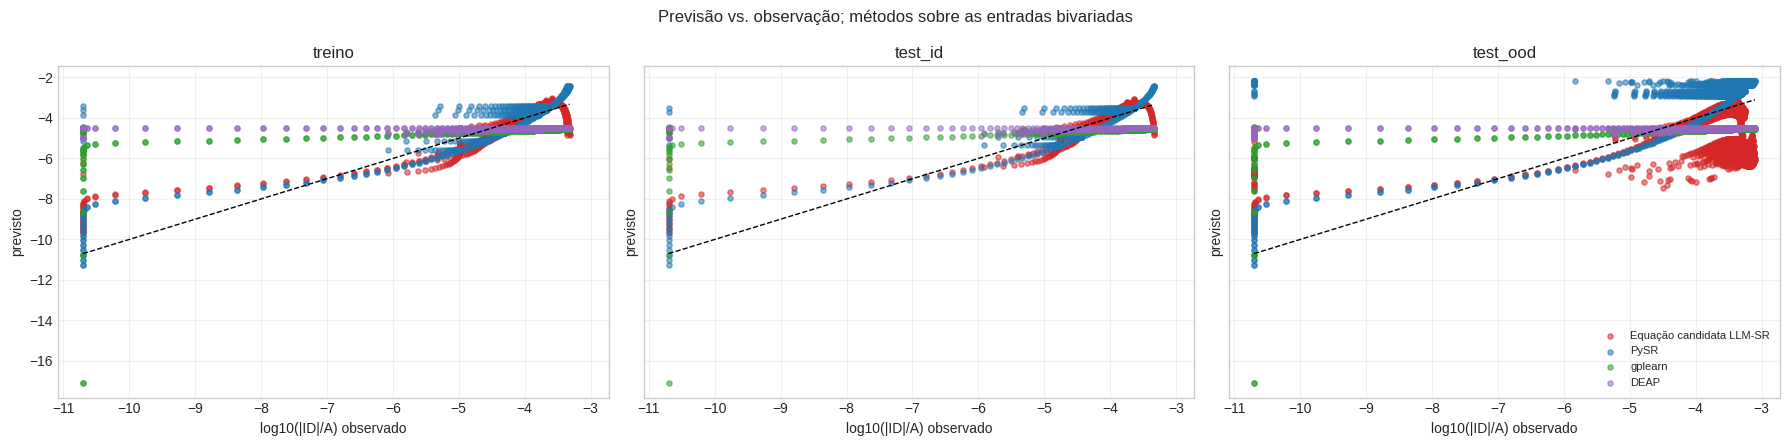

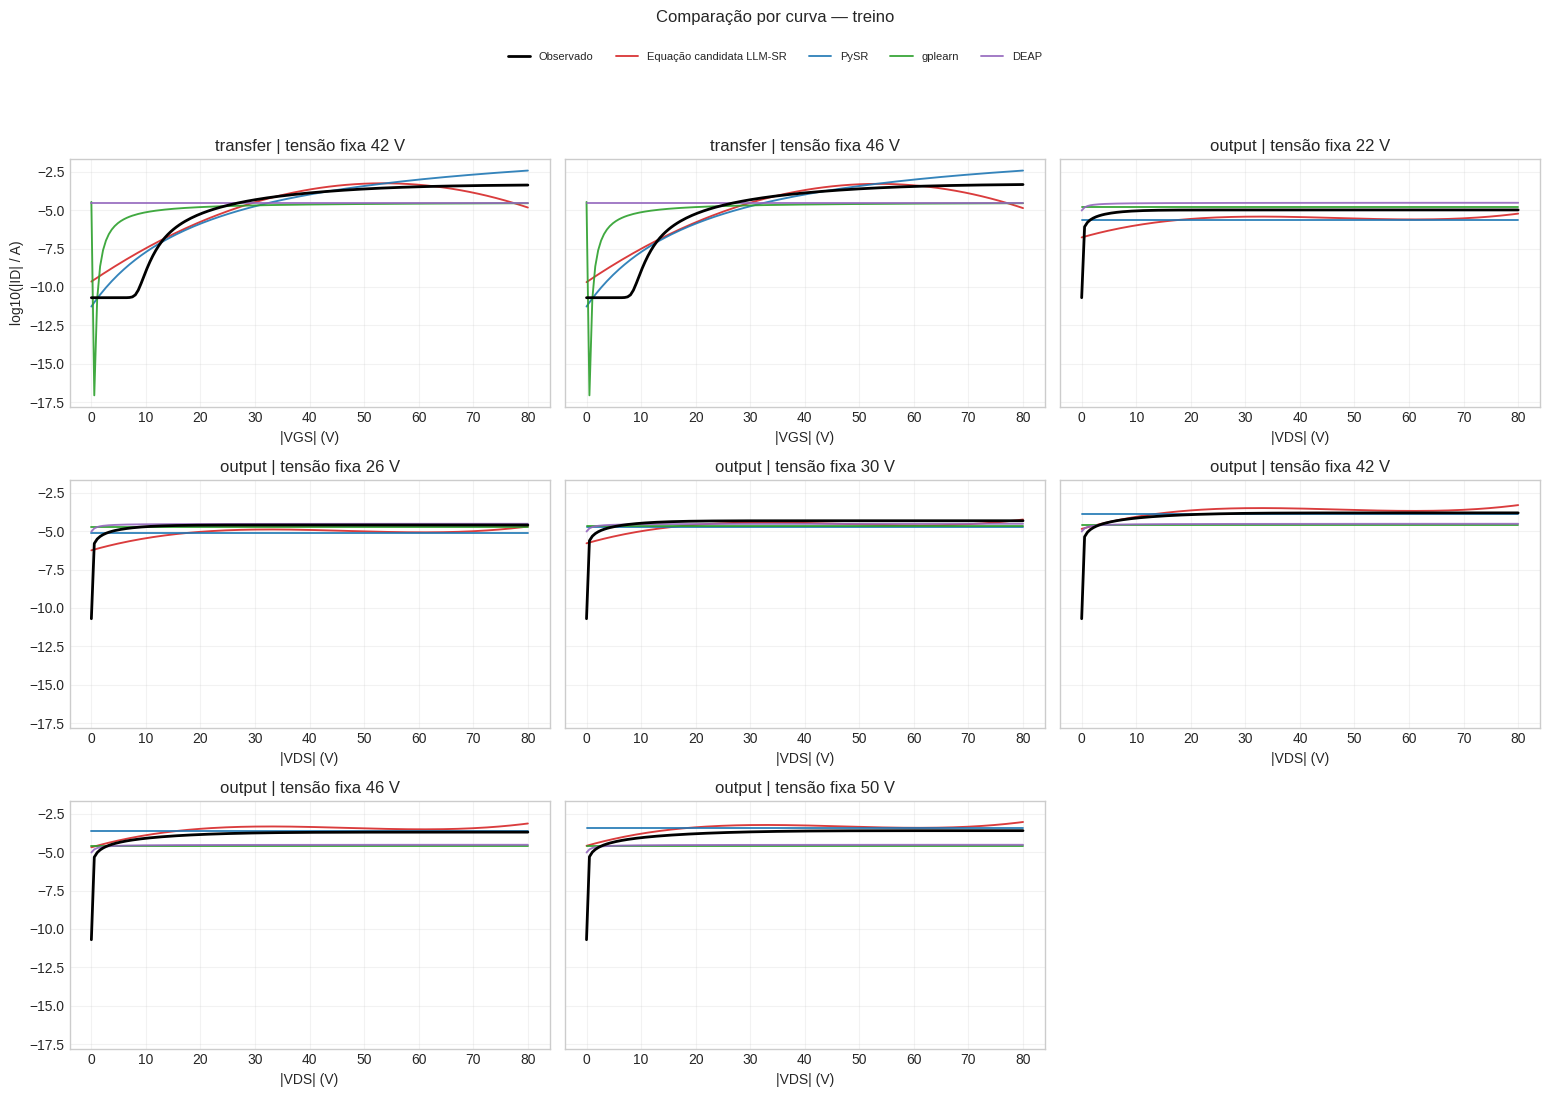

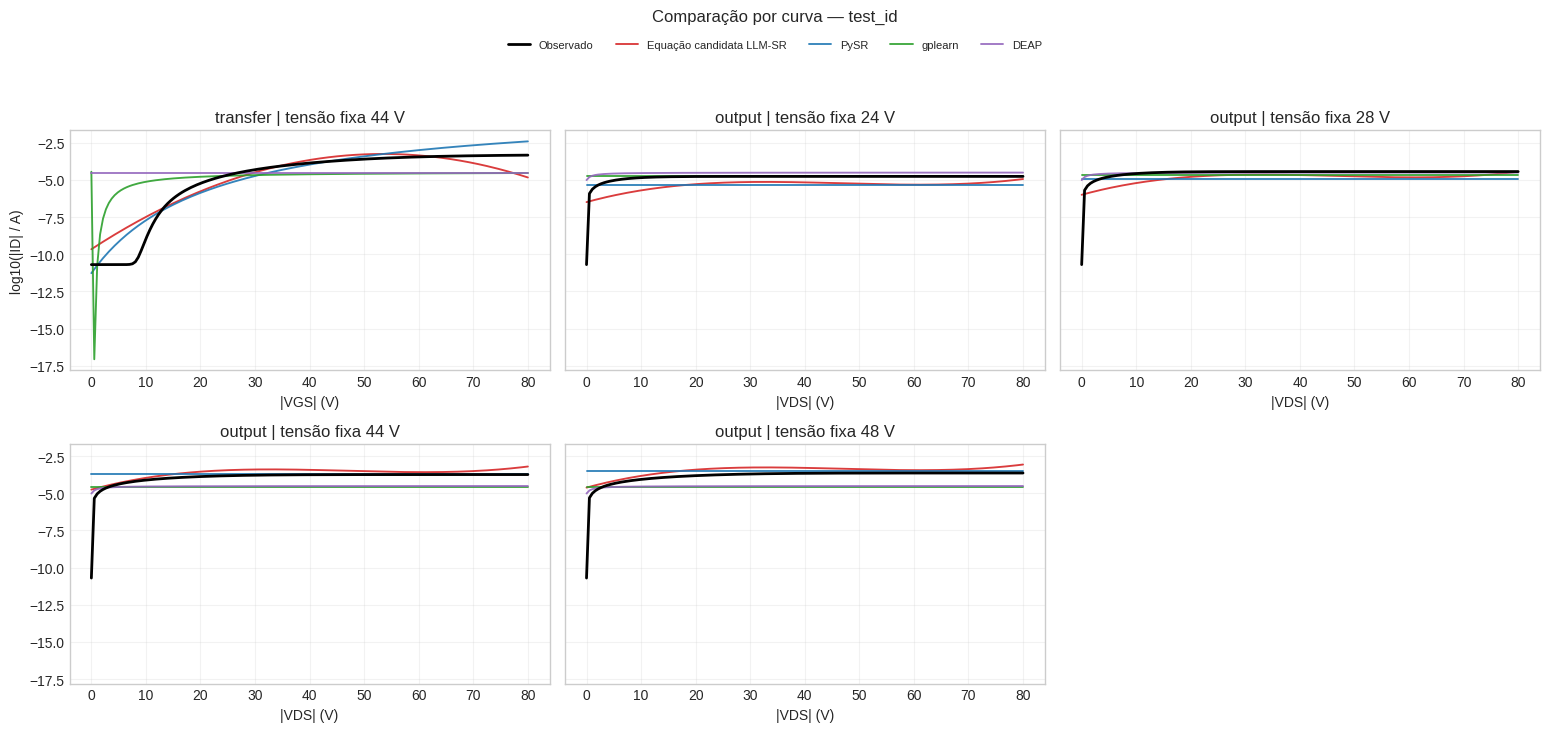

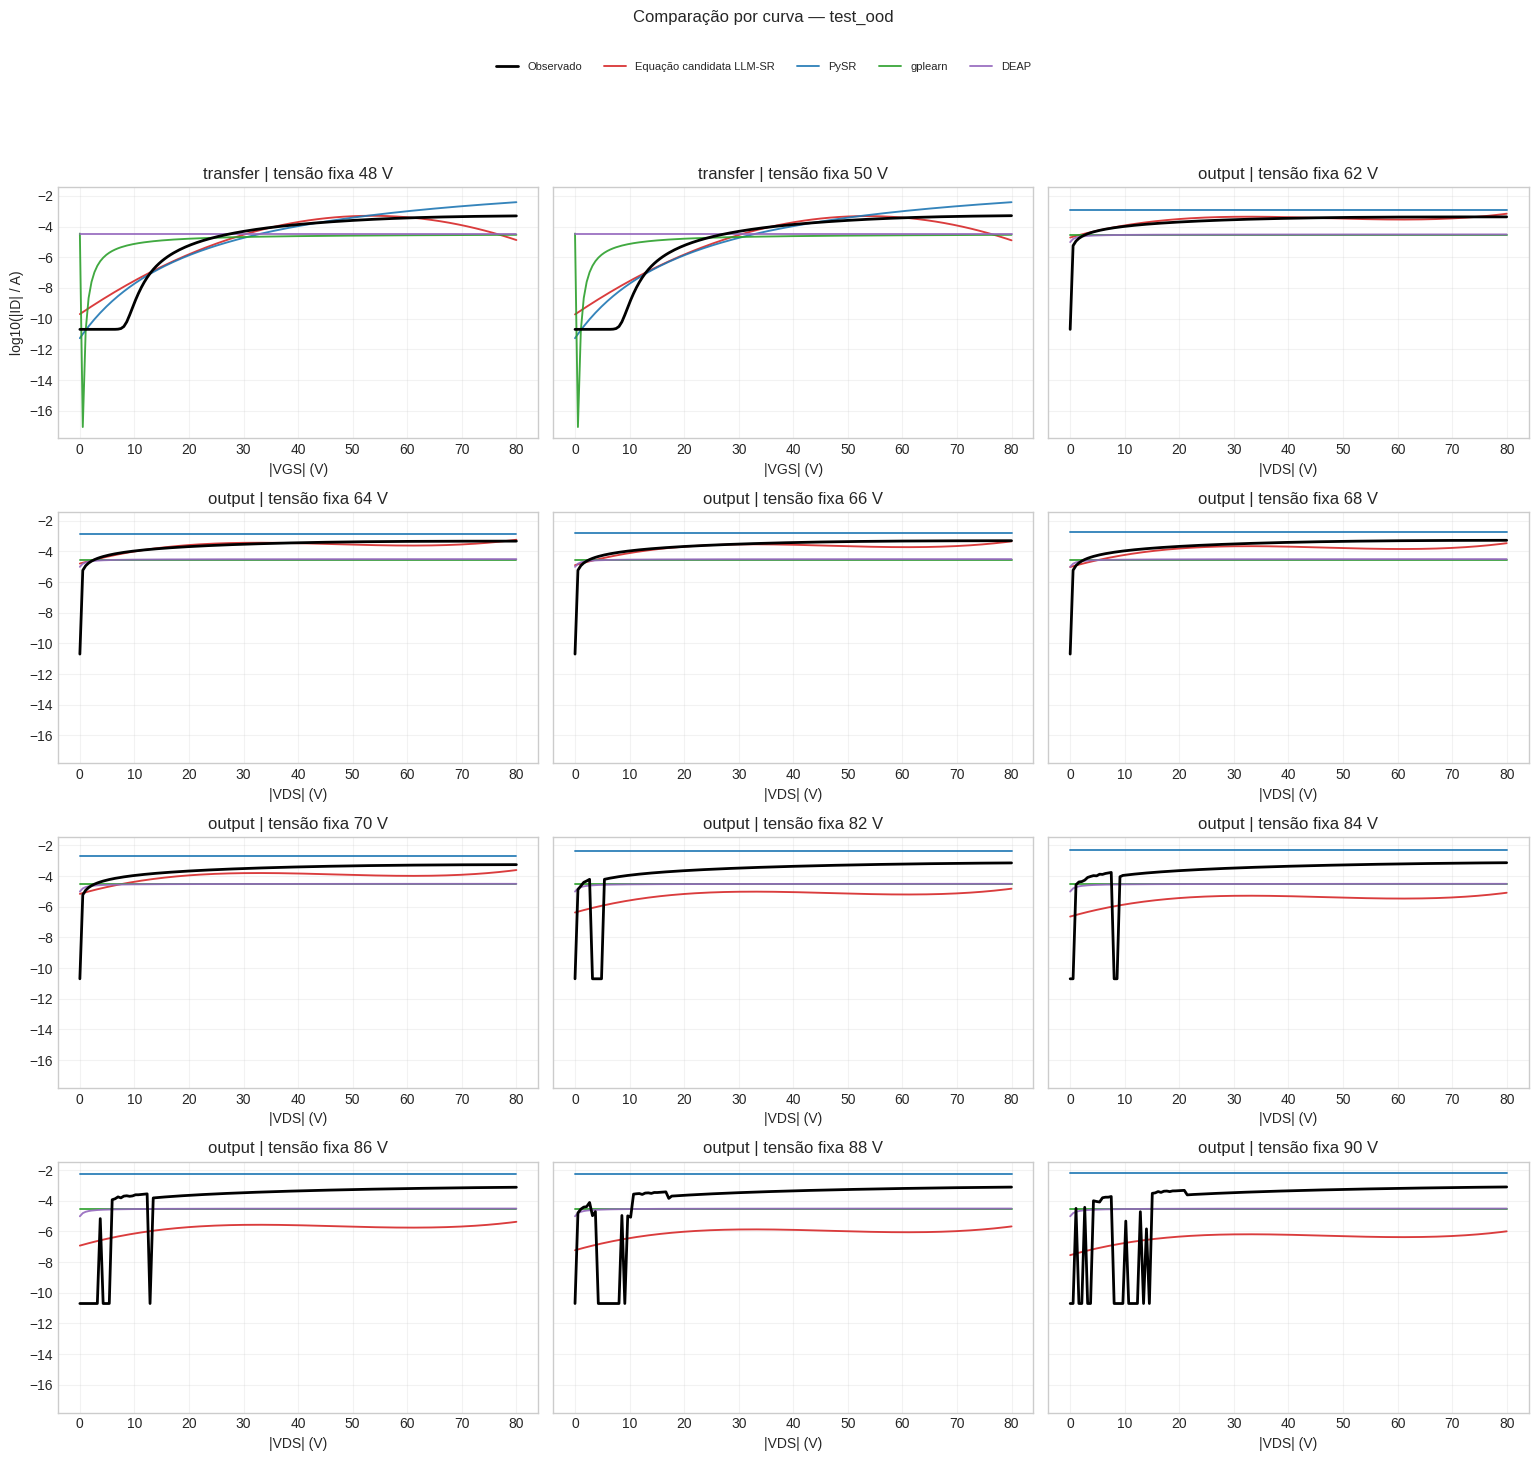

,conjunto,curve_id,família,tensão_fixa_V,método,MSE_log10,RMSE_log10,MAE_log10,R2,fator_multiplicativo_RMSE
38,test_id,output-neg24V_synth_001,output,24.0,gplearn,0.26737,0.51708,0.11902,-0.05594,3.28914
39,test_id,output-neg24V_synth_001,output,24.0,DEAP,0.31159,0.55821,0.32356,-0.23058,3.61582
36,test_id,output-neg24V_synth_001,output,24.0,Equação candidata LLM-SR,0.43352,0.65842,0.55633,-0.71209,4.55430
37,test_id,output-neg24V_synth_001,output,24.0,PySR,0.50807,0.71279,0.58854,-1.00653,5.16169
43,test_id,output-neg28V_synth_003,output,28.0,DEAP,0.23581,0.48560,0.13059,0.17421,3.05917
...,...,...,...,...,...,...,...,...,...,...
3,treino,transfer-neg42V_synth_000,transfer,42.0,DEAP,5.81068,2.41054,1.60436,-0.04168,257.35674
5,treino,transfer-neg46V_synth_002,transfer,46.0,PySR,0.50548,0.71097,0.54981,0.90987,5.14008
4,treino,transfer-neg46V_synth_002,transfer,46.0,Equação candidata LLM-SR,0.73687,0.85841,0.58304,0.86861,7.21792
6,treino,transfer-neg46V_synth_002,transfer,46.0,gplearn,3.83288,1.95777,1.40083,0.31657,90.73471


Métricas por curva: /home/ymws/Documentos/llm-sr/OTFT-SR/results/org4_synthetic_notebook_curves/metrics_by_curve.csv
Gráficos individuais e agrupados: /home/ymws/Documentos/llm-sr/OTFT-SR/results/org4_synthetic_notebook_curves
Equações selecionadas:
Equação candidata LLM-SR:
def equation(gate_voltage_abs: np.ndarray, drain_voltage_abs: np.ndarray, parameters: np.ndarray) -> np.ndarray:
    """Modelo empírico bivariado para log10(|ID|/A)."""
    """Further improved version of the function that includes a cubic term for drain_voltage_abs and a quadratic term for gate_voltage_abs."""
    return (
        parameters[0]
        + parameters[1] * gate_voltage_abs
        + parameters[2] * gate_voltage_abs**2
        + parameters[3] * drain_voltage_abs
        + parameters[4] * drain_voltage_abs**2
        + parameters[5] * drain_voltage_abs**3
    )
PySR: -244.97844 / (VGS_abs_V + 21.728468)
gplearn: sub(div(add(1.639, 1.910), -1.028), div(add(add(X0, add(1.639, 1.910)), add(1.273, 1.910)), 

In [8]:
comparison_models = {
    "Equação candidata LLM-SR": candidate_predictions,
}
for classical_method in baseline_equations:
    comparison_models[classical_method] = {
        split_name: baseline_predictions[(classical_method, split_name)]
        for split_name in baseline_sets
    }

comparison_records = []
for method_name, split_predictions in comparison_models.items():
    for split_name, prediction in split_predictions.items():
        observed = baseline_sets[split_name][TARGET_COLUMN].to_numpy(dtype=float)
        comparison_records.append({
            "método": method_name,
            "conjunto": split_name,
            **calculate_log_metrics(observed, np.asarray(prediction, dtype=float)),
        })

method_order = ["Equação candidata LLM-SR", "PySR", "gplearn", "DEAP"]
comparison_df = pd.DataFrame(comparison_records)
if comparison_df.empty:
    print("Nenhuma previsão disponível para a comparação.")
else:
    comparison_df["método"] = pd.Categorical(comparison_df["método"], categories=method_order, ordered=True)
    comparison_df = comparison_df.sort_values(["método", "conjunto"]).reset_index(drop=True)
    display(comparison_df.round(6))
    comparison_pivot = comparison_df.pivot(index="método", columns="conjunto",
                                            values=["RMSE_log10", "MAE_log10", "R2"])
    display(comparison_pivot.round(6))

    prediction_colors = {
        "Equação candidata LLM-SR": "tab:red", "PySR": "tab:blue",
        "gplearn": "tab:green", "DEAP": "tab:purple",
    }
    split_names = list(baseline_sets)
    if len(FEATURE_COLUMNS) == 1:
        fig, axes = plt.subplots(1, len(split_names), figsize=(6 * len(split_names), 4.5), sharey=True)
        if len(split_names) == 1:
            axes = [axes]
        for ax, split_name in zip(axes, split_names):
            frame = baseline_sets[split_name]
            x_values = frame[FEATURE_COLUMNS[0]].to_numpy(dtype=float)
            y_observed = frame[TARGET_COLUMN].to_numpy(dtype=float)
            order = np.argsort(x_values)
            ax.scatter(x_values, y_observed, color="black", s=22, label="Dados observados", zorder=5)
            for method_name, split_predictions in comparison_models.items():
                if split_name in split_predictions:
                    ax.plot(x_values[order], np.asarray(split_predictions[split_name])[order],
                            color=prediction_colors.get(method_name), linewidth=1.8,
                            marker=".", markersize=5, label=method_name)
            ax.set(xlabel="|VGS| (V)", title=SPLIT_LABELS.get(split_name, split_name))
            ax.grid(True, alpha=.3)
        axes[0].set_ylabel("log10(|ID| / A)")
        axes[-1].legend(loc="best", fontsize=8)
        fig.suptitle("Curvas previstas pelos métodos simbólicos")
    else:
        fig, axes = plt.subplots(1, len(split_names), figsize=(6 * len(split_names), 4.5), sharex=True, sharey=True)
        if len(split_names) == 1:
            axes = [axes]
        for ax, split_name in zip(axes, split_names):
            observed = baseline_sets[split_name][TARGET_COLUMN].to_numpy(dtype=float)
            for method_name, split_predictions in comparison_models.items():
                if split_name not in split_predictions:
                    continue
                ax.scatter(observed, split_predictions[split_name], s=14, alpha=.55,
                           color=prediction_colors.get(method_name), label=method_name)
            limits = [observed.min(), observed.max()]
            ax.plot(limits, limits, "k--", lw=1)
            ax.set(title=SPLIT_LABELS.get(split_name, split_name),
                   xlabel="log10(|ID|/A) observado", ylabel="previsto")
            ax.grid(True, alpha=.3)
        axes[-1].legend(loc="best", fontsize=8)
        fig.suptitle("Previsão vs. observação; métodos sobre as entradas bivariadas")
    plt.tight_layout()
    curve_output_directory = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_curves"
    curve_output_directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(curve_output_directory / "comparacao_agregada.png", dpi=160, bbox_inches="tight")
    fig.savefig(curve_output_directory / "comparacao_agregada.svg", bbox_inches="tight")
    plt.show()

# Avaliação e curvas de previsão alinhadas por curva individual.
curve_metric_records = []
curve_output_directory = OTFT_SR_ROOT / "results" / f"{RUN_NAME}_curves"
curve_output_directory.mkdir(parents=True, exist_ok=True)
for split_name, split_frame in baseline_sets.items():
    if "curve_id" in split_frame.columns:
        curve_groups = list(split_frame.groupby("curve_id", sort=False))
    else:
        curve_groups = [(RUN_NAME, split_frame)]

    number_of_curves = len(curve_groups)
    number_of_columns = min(3, number_of_curves)
    number_of_rows = int(np.ceil(number_of_curves / number_of_columns))
    figure, axes = plt.subplots(
        number_of_rows, number_of_columns,
        figsize=(5.2 * number_of_columns, 3.5 * number_of_rows),
        sharey=True, squeeze=False,
    )
    axes_flat = axes.ravel()
    sweep_column = "sweep_voltage_abs_V" if "sweep_voltage_abs_V" in split_frame.columns else FEATURE_COLUMNS[0]

    for curve_index, (curve_id, curve_frame) in enumerate(curve_groups):
        axis = axes_flat[curve_index]
        row_indices = curve_frame.index.to_numpy(dtype=int)
        sweep_voltage = curve_frame[sweep_column].to_numpy(dtype=float)
        sort_order = np.argsort(sweep_voltage)
        observed = curve_frame[TARGET_COLUMN].to_numpy(dtype=float)
        axis.plot(
            sweep_voltage[sort_order], observed[sort_order],
            color="black", linewidth=2.0, label="Observado", zorder=5,
        )

        for method_name, split_predictions in comparison_models.items():
            if split_name not in split_predictions:
                continue
            predicted = np.asarray(split_predictions[split_name], dtype=float)[row_indices]
            axis.plot(
                sweep_voltage[sort_order], predicted[sort_order],
                color=prediction_colors.get(method_name), linewidth=1.35,
                alpha=.9, label=method_name,
            )
            curve_metric_records.append({
                "conjunto": split_name,
                "curve_id": curve_id,
                "família": curve_frame["curve_family"].iloc[0] if "curve_family" in curve_frame else "transfer",
                "tensão_fixa_V": curve_frame["fixed_voltage_abs_V"].iloc[0] if "fixed_voltage_abs_V" in curve_frame else np.nan,
                "método": method_name,
                **calculate_log_metrics(observed, predicted),
            })

        if "curve_family" in curve_frame.columns:
            curve_title = f"{curve_frame['curve_family'].iloc[0]} | tensão fixa {curve_frame['fixed_voltage_abs_V'].iloc[0]:g} V"
        else:
            curve_title = str(curve_id)
        if "curve_family" in curve_frame.columns:
            family = str(curve_frame["curve_family"].iloc[0]).lower()
            sweep_label = "|VGS| (V)" if "transfer" in family else "|VDS| (V)"
        else:
            sweep_label = f"|{FEATURE_COLUMNS[0].replace('_abs_V', '')}| (V)"
        axis.set(title=curve_title, xlabel=sweep_label)
        axis.grid(True, alpha=.25)

        individual_figure, individual_axis = plt.subplots(figsize=(6.4, 4.4))
        individual_axis.plot(sweep_voltage[sort_order], observed[sort_order], color="black", linewidth=2.0, label="Observado", zorder=5)
        for method_name, split_predictions in comparison_models.items():
            if split_name not in split_predictions:
                continue
            predicted = np.asarray(split_predictions[split_name], dtype=float)[row_indices]
            individual_axis.plot(sweep_voltage[sort_order], predicted[sort_order], color=prediction_colors.get(method_name), linewidth=1.6, label=method_name)
        individual_axis.set(title=f"{SPLIT_LABELS.get(split_name, split_name)} | {curve_title}", xlabel=sweep_label, ylabel="log10(|ID| / A)")
        individual_axis.grid(True, alpha=.25)
        individual_axis.legend(loc="best", fontsize=8)
        individual_figure.tight_layout()
        safe_curve_id = "".join(character if character.isalnum() or character in "-_" else "_" for character in str(curve_id))
        individual_figure.savefig(curve_output_directory / f"{split_name}_{safe_curve_id}.png", dpi=160, bbox_inches="tight")
        individual_figure.savefig(curve_output_directory / f"{split_name}_{safe_curve_id}.svg", bbox_inches="tight")
        plt.close(individual_figure)

    for unused_axis in axes_flat[number_of_curves:]:
        unused_axis.set_visible(False)
    axes_flat[0].set_ylabel("log10(|ID| / A)")
    legend_handles, legend_labels = axes_flat[0].get_legend_handles_labels()
    figure.legend(legend_handles, legend_labels, loc="upper center", ncol=min(5, len(legend_labels)),
                  bbox_to_anchor=(.5, 1.01), fontsize=8)
    figure.suptitle(f"Comparação por curva — {SPLIT_LABELS.get(split_name, split_name)}", y=1.04)
    figure.tight_layout(rect=(0, 0, 1, .96))
    figure.savefig(curve_output_directory / f"{split_name}_curves.png", dpi=160, bbox_inches="tight")
    figure.savefig(curve_output_directory / f"{split_name}_curves.svg", bbox_inches="tight")
    plt.show()

curve_metrics_df = pd.DataFrame(curve_metric_records)
if not curve_metrics_df.empty:
    curve_metrics_path = curve_output_directory / "metrics_by_curve.csv"
    curve_metrics_df.to_csv(curve_metrics_path, index=False)
    display(curve_metrics_df.sort_values(["conjunto", "curve_id", "RMSE_log10"]).round(5))
    print("Métricas por curva:", curve_metrics_path)
    print("Gráficos individuais e agrupados:", curve_output_directory)

# Consolida os painéis por conjunto em um PDF multipágina.
from matplotlib.backends.backend_pdf import PdfPages
combined_pdf_path = curve_output_directory / "comparacao_todas_curvas.pdf"
with PdfPages(combined_pdf_path) as combined_pdf:
    for split_name in baseline_sets:
        panel_path = curve_output_directory / f"{split_name}_curves.png"
        if panel_path.exists():
            panel_figure, panel_axis = plt.subplots(figsize=(12, 8))
            panel_axis.imshow(plt.imread(panel_path))
            panel_axis.axis("off")
            panel_figure.tight_layout()
            combined_pdf.savefig(panel_figure, bbox_inches="tight")
            plt.close(panel_figure)

print("Equações selecionadas:")
print("Equação candidata LLM-SR:")
print(best_function_source.strip())
for method_name, expression in baseline_equations.items():
    print(f"{method_name}: {expression}")

# Exportação das expressões, especificações completas e versões dos métodos.
import importlib.metadata
import platform

def json_compatible(value):
    if isinstance(value, dict):
        return {str(key): json_compatible(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_compatible(item) for item in value]
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, (str, int, float, bool)) or value is None:
        return value
    return repr(value)

model_specifications = {
    "execucao": {
        "run_name": RUN_NAME, "dataset_mode": DATASET_MODE,
        "feature_columns": FEATURE_COLUMNS, "target_column": TARGET_COLUMN,
        "train_rows": int(len(train_df)),
        "split_rows": {name: int(len(frame)) for name, frame in baseline_sets.items()},
        "python_version": platform.python_version(),
    },
    "equacao_candidata_LLM_SR": {
        "status": "executado", "score_logado": float(best_score_logged),
        "fonte": best_function_source.strip(),
        "parametros_reajustados_treino": np.asarray(candidate_parameters, dtype=float).tolist(),
    },
    "configuracao_comum": {"seed": BASELINE_SEED, "run_classic_baselines": RUN_CLASSIC_BASELINES},
    "metodos": {},
}
selected_equations = {"Equação candidata LLM-SR": best_function_source.strip()}
models_by_name = {
    "PySR": globals().get("pysr_model"),
    "gplearn": globals().get("gplearn_model"),
    "DEAP": globals().get("hall_of_fame"),
}
for method_name in ("PySR", "gplearn", "DEAP"):
    expression = baseline_equations.get(method_name)
    selected_equations[method_name] = expression if expression is not None else f"Indisponível: {baseline_status[method_name]}"
    method_specification = {"status": baseline_status[method_name], "equacao_selecionada": expression}
    model = models_by_name[method_name]
    if method_name in ("PySR", "gplearn"):
        if model is not None:
            method_specification["parametros"] = json_compatible(model.get_params(deep=True))
        package_name = "pysr" if method_name == "PySR" else "gplearn"
    else:
        method_specification["parametros"] = {
            "population_size": DEAP_POPULATION_SIZE, "generations": DEAP_GENERATIONS,
            "tournament_size": DEAP_TOURNAMENT_SIZE, "crossover_probability": 0.5,
            "mutation_probability": 0.25, "initialization": "genHalfAndHalf(min_=1, max_=3)",
            "mutation_expression": "genFull(min_=0, max_=2)", "maximum_tree_height": 8,
            "primitive_operators": ["add", "sub", "mul", "protected_division"],
            "ephemeral_constant_range": [-2.0, 2.0], "seed": BASELINE_SEED,
            "fitness": "MSE + 1e-5 * número_de_nós; inválidos penalizados com 1e12 + tamanho",
        }
        package_name = "deap"
    try:
        method_specification["versao"] = importlib.metadata.version(package_name)
    except importlib.metadata.PackageNotFoundError:
        method_specification["versao"] = None
    model_specifications["metodos"][method_name] = method_specification

model_specifications["configuracao_comum"].update({
    "PySR": {"niterations": PYSR_ITERATIONS, "populations": PYSR_POPULATIONS,
             "population_size": PYSR_POPULATION_SIZE, "maxsize": 18,
             "binary_operators": ["+", "-", "*", "/"], "deterministic": True,
             "parallelism": "serial", "random_state": BASELINE_SEED},
    "gplearn": {"generations": GPLEARN_GENERATIONS,
                "population_size": GPLEARN_POPULATION_SIZE,
                "function_set": ["add", "sub", "mul", "div"], "metric": "mse",
                "parsimony_coefficient": 0.001, "const_range": [-2.0, 2.0],
                "random_state": BASELINE_SEED, "n_jobs": 1},
})
model_specifications_path = curve_output_directory / "model_specifications.json"
equations_path = curve_output_directory / "selected_equations.txt"
model_specifications_path.write_text(json.dumps(model_specifications, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
equations_path.write_text("\n\n".join(f"## {name}\n{equation}" for name, equation in selected_equations.items()), encoding="utf-8")
print("Especificações completas:", model_specifications_path)
print("Equações selecionadas:", equations_path)
print("PDF com os painéis de todos os conjuntos:", combined_pdf_path)

## 8. Interpretação da comparação

Use test_id para curvas reservadas dentro do suporte de treino e test_ood para extrapolação além das faixas por família documentadas no manifesto. Métricas por curva mostram diferenças entre famílias e polarizações. O score LLM-SR mede ajuste apenas em treino.

## 9. Síntese e limites

A candidata LLM-SR é reajustada em treino antes da avaliação nos conjuntos reservados. Métodos clássicos usam as mesmas entradas e o mesmo treino. Generalização para outros dispositivos não é inferida destas curvas sintéticas.